In [136]:
import torch
import numpy as np
import pandas as pd

from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim

import os
import matplotlib.pyplot as plt



In [137]:
class RuscoDataset():

    def __init__(self, data_file):

        all_data = pd.read_csv( data_file, dtype={'xDate':np.float64,
                                                    'yDate':np.float64,
                                                    't2m_now':np.float64,
                                                    't2m_next':np.float64 } )

        self.input_data = (all_data[ ["xDate", "yDate", "t2m_now"] ]).copy()
        self.pred_temps = (all_data[ ["t2m_next"] ]).copy()
    
    def __len__(self):
        return len(self.pred_temps)
    
    def __getitem__(self, indx):

        xDate = self.input_data["xDate"].iloc[indx].item()
        yDate = self.input_data["yDate"].iloc[indx].item()
        now_temp = self.input_data["t2m_now"].iloc[indx].item()
        next_temp = self.pred_temps["t2m_next"].iloc[indx].item()

        dati_input = (xDate, yDate, now_temp)

        return torch.as_tensor(dati_input, dtype=torch.float32), torch.as_tensor(next_temp, dtype=torch.float32)



In [138]:
train_dataset = RuscoDataset("/home/federico_menegazzo/Desktop/Programming/python_projects/analisi_dati_ki/poggio_rusco/train_rusco_data.csv")
test_dataset = RuscoDataset("/home/federico_menegazzo/Desktop/Programming/python_projects/analisi_dati_ki/poggio_rusco/test_rusco_data.csv")

print(len(train_dataset))
print(len(test_dataset))


train_dataloader = DataLoader(train_dataset, batch_size=1024, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=True)

2921
1095


In [139]:
class StdNet(nn.Module):

    def __init__(self):

        super().__init__()
        self.lay1 = nn.Linear(3, 512)
        self.lay2 = nn.Linear(512, 512)
        self.lay3 = nn.Linear(512, 512)
        self.lay4 = nn.Linear(512, 1)

    def forward(self, x):

        x = torch.sigmoid(self.lay1(x))
        x = torch.sigmoid(self.lay2(x))
        x = torch.sigmoid(self.lay3(x))
        x = self.lay4(x)

        return x[:, 0]



KiNet = StdNet()
#net_parameters = torch.load("./NetParams/KiNetV1.pth",weights_only=True)
#KiNet.load_state_dict(net_parameters)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

KiNet = KiNet.to(device)


cuda:0


In [140]:

input_data, out_temp = next( iter(test_dataloader) )

print(f"dati input: {input_data}")
print(f"temperatura effettiva {out_temp}")
print(f"temperatura calcolata { KiNet(input_data.to(device)) }")

dati input: tensor([[ 0.3577,  0.9338, -0.0205]])
temperatura effettiva tensor([-0.4822])
temperatura calcolata tensor([-0.1682], device='cuda:0', grad_fn=<SelectBackward0>)


In [141]:
criterion = nn.MSELoss(reduction='mean')
optimizer = optim.Adam(KiNet.parameters(),lr=0.001)

for epoch in range(1000):

    epoch_loss = 0

    for j, data in enumerate(train_dataloader, 0):

        input_data, out_temp = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()

        net_output = KiNet(input_data)
        loss = criterion(net_output, out_temp)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()


    print(f"epoch: {epoch}, loss: {epoch_loss}")

epoch: 0, loss: 396.2728729248047
epoch: 1, loss: 249.05859375
epoch: 2, loss: 176.8680076599121
epoch: 3, loss: 150.2369728088379
epoch: 4, loss: 139.87093353271484
epoch: 5, loss: 135.31838989257812
epoch: 6, loss: 133.46383666992188
epoch: 7, loss: 132.72562789916992
epoch: 8, loss: 132.78429412841797
epoch: 9, loss: 132.2312126159668
epoch: 10, loss: 130.8791160583496
epoch: 11, loss: 128.1013412475586
epoch: 12, loss: 124.4675178527832
epoch: 13, loss: 119.65633773803711
epoch: 14, loss: 114.10404968261719
epoch: 15, loss: 107.88569259643555
epoch: 16, loss: 100.58393478393555
epoch: 17, loss: 92.64763641357422
epoch: 18, loss: 84.3093376159668
epoch: 19, loss: 77.16341590881348
epoch: 20, loss: 71.8569278717041
epoch: 21, loss: 65.47194290161133
epoch: 22, loss: 58.73609733581543
epoch: 23, loss: 54.046621322631836
epoch: 24, loss: 49.545472145080566
epoch: 25, loss: 44.913909912109375
epoch: 26, loss: 41.380672454833984
epoch: 27, loss: 38.4059362411499
epoch: 28, loss: 35.37067

In [142]:
def test_net(net, test_loader):

    avg_error = 0

    for j, data in enumerate(test_loader, 0):

        input_data, out_temp = data[0].to(device), data[1].to(device)
        
        net_output = net(input_data)
        avg_error += (torch.abs(net_output - out_temp)) * (1/len(test_loader))

    return avg_error



print(f"test results: {test_net(KiNet, test_dataloader)}")

    

test results: tensor([1.5385], device='cuda:0', grad_fn=<AddBackward0>)


In [143]:

torch.save(KiNet.state_dict(), f'./NetParams/KiNetV1.pth')

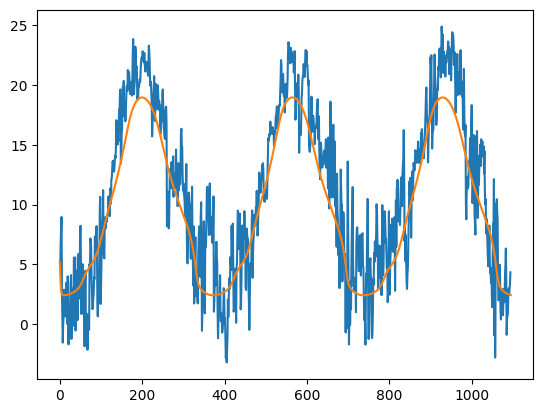

In [144]:

raw_test_data = pd.read_csv( "/home/federico_menegazzo/Desktop/Programming/python_projects/analisi_dati_ki/poggio_rusco/test_rusco_data.csv", dtype = {'day':np.int32,
                                                                           'month':np.int32,
                                                                           'year':np.int32,
                                                                           't2m_now':np.float32,
                                                                           't2m_next':np.float32} )


x0 = 5.159420000000011
iterative_model = [x0]



for indx, entry in raw_test_data.iterrows():

    giorno = entry["xDate"]
    mese = entry["yDate"]

    input_entry = np.array([giorno, mese, x0])

    tensor_input_entry = torch.as_tensor( input_entry, dtype=torch.float32).unsqueeze(0)

    pred_temp = KiNet(tensor_input_entry.to(device))
    iterative_model.append(pred_temp[0].cpu().detach().numpy())

    x0 = pred_temp[0].cpu().detach().numpy()



plt.plot(raw_test_data["t2m_now"].values)
plt.plot(iterative_model)
plt.show()